# Step 3 – Exploratory Data Analysis (EDA)
**Project:** Paper Leak Sentiment Analysis Using Federated Learning

This notebook explores the two datasets:

| Part | Dataset | Rows |
|---|---|---|
| A | `data/raw/paper_leaks.csv` – real paper-leak incidents in India (2004–2026) | 110 |
| B | `data/processed/paper_leak_comments.csv` – labeled public comments grounded in those incidents | 1,00,002 |

Every chart is saved to `results/figures/` for the report and slides.

In [1]:
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "results" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / "results" / "tables";  TAB.mkdir(parents=True, exist_ok=True)

inc = pd.read_csv(ROOT / "data/raw/paper_leaks.csv", parse_dates=["date"])
df  = pd.read_csv(ROOT / "data/processed/paper_leak_comments.csv", parse_dates=["posted_at"])
print(f"Incidents: {len(inc):,}   Comments: {len(df):,}")

Incidents: 110   Comments: 100,002


### Chart style
One consistent look for every figure: light surface, thin marks, quiet grid.
Sentiment uses a **diverging** scheme: red = negative, gray = neutral, blue = positive.
Platforms (the future FL clients) use a fixed categorical order, so each platform keeps the same color in every chart.

In [2]:
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SENT  = {"negative": "#e34948", "neutral": "#898781", "positive": "#2a78d6"}
ORDER = ["negative", "neutral", "positive"]
CAT   = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
PLATFORMS = ["YouTube", "X", "Instagram", "Reddit", "NewsPortal"]
PCOL  = dict(zip(PLATFORMS, CAT))
BLUE  = CAT[0]

from matplotlib import font_manager
FONT = "Segoe UI" if any(f.name == "Segoe UI" for f in font_manager.fontManager.ttflist) else "DejaVu Sans"
plt.rcParams.update({
    "font.family": FONT, "font.size": 10,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "savefig.dpi": 200, "savefig.bbox": "tight",
})

def title(ax, main, sub=None):
    ax.set_title(main, loc="left", fontsize=13, fontweight="bold", color=INK, pad=24 if sub else 10)
    if sub:
        ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=9.5, color=INK2, va="bottom")

def kfmt(x, _=None):
    return f"{x/1000:g}k" if x >= 1000 else f"{x:g}"

def short(name, n=38):
    name = re.sub(r"\s*\(.*?\)", "", name).strip()
    return name if len(name) <= n else name[:n].rsplit(" ", 1)[0] + "…"

def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()

def stacked_share(ax, table, colors, label_min=0.06):
    """100% horizontal stacked bars with a 2px surface gap and direct % labels."""
    left = np.zeros(len(table))
    for col in table.columns:
        vals = table[col].values
        ax.barh(table.index, vals, left=left, color=colors[col], edgecolor=SURFACE, linewidth=2, height=0.62, label=col.capitalize())
        for i, (l, v) in enumerate(zip(left, vals)):
            if v >= label_min:
                ax.text(l + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="#ffffff")
        left += vals
    ax.set_xlim(0, 1); ax.grid(False); ax.invert_yaxis()
    ax.set_xticks([0, .25, .5, .75, 1]); ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"])
    ax.legend(ncol=len(table.columns), loc="upper left", bbox_to_anchor=(0, -0.12))

---
## Part A – The incidents (problem background)

### A1. Paper leaks per year

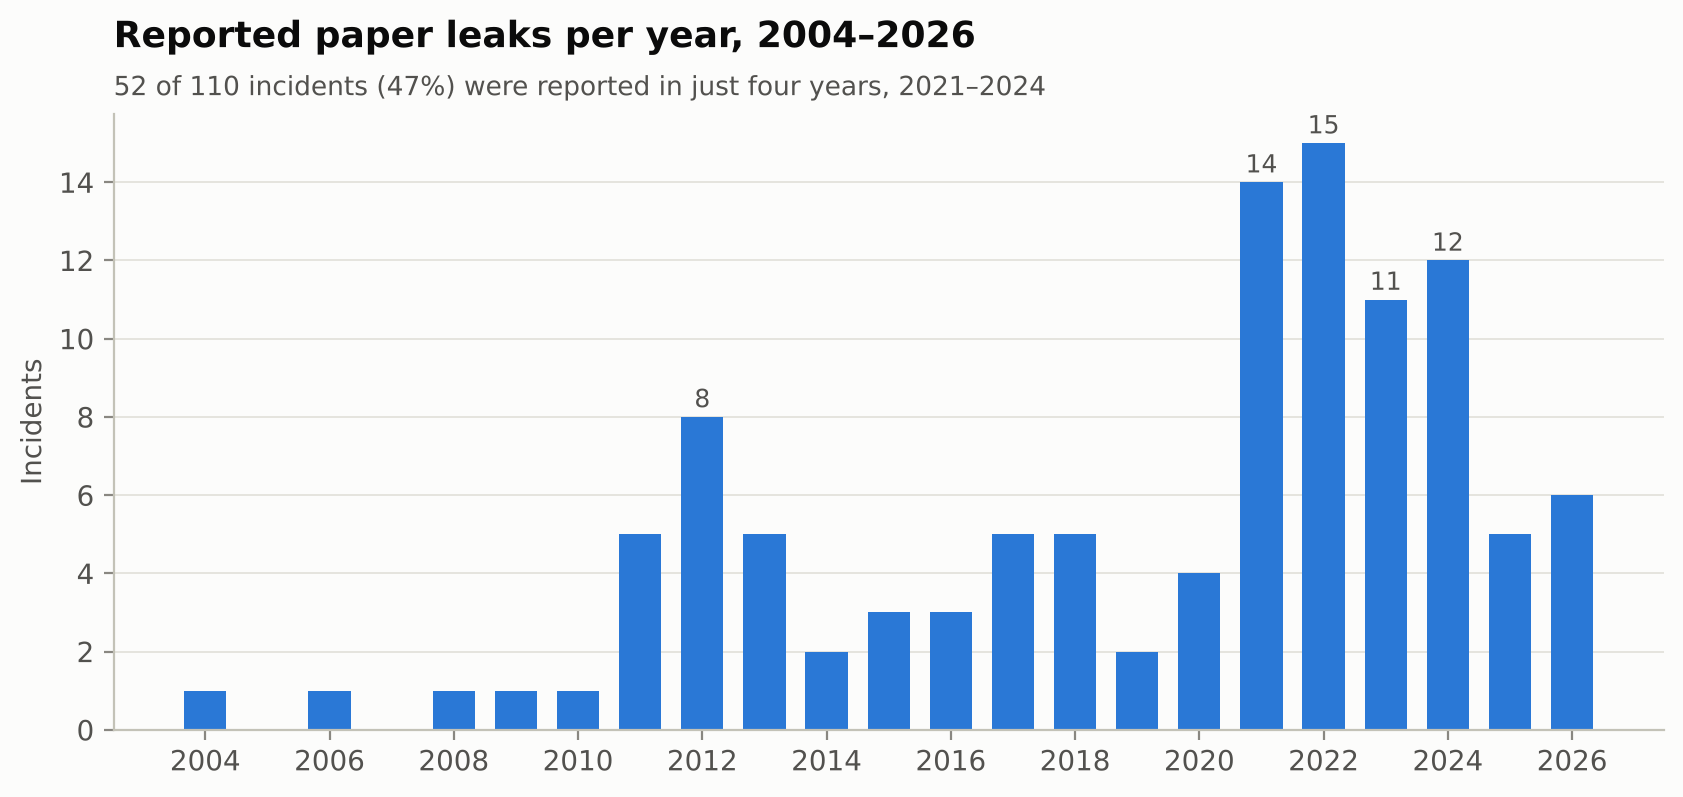

In [3]:
yr = inc.date.dt.year.value_counts().sort_index().reindex(range(2004, 2027), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(yr.index, yr.values, color=BLUE, width=0.68)
ax.grid(axis="x", visible=False)
for x, v in yr.items():
    if v >= 8:
        ax.text(x, v + 0.25, str(v), ha="center", fontsize=9, color=INK2)
recent = yr.loc[2021:2024].sum()
title(ax, "Reported paper leaks per year, 2004–2026",
      f"{recent} of {len(inc)} incidents ({recent/len(inc):.0%}) were reported in just four years, 2021–2024")
ax.set_ylabel("Incidents"); ax.set_xticks(range(2004, 2027, 2))
save(fig, "A1_incidents_per_year")

### A2. States with the most incidents

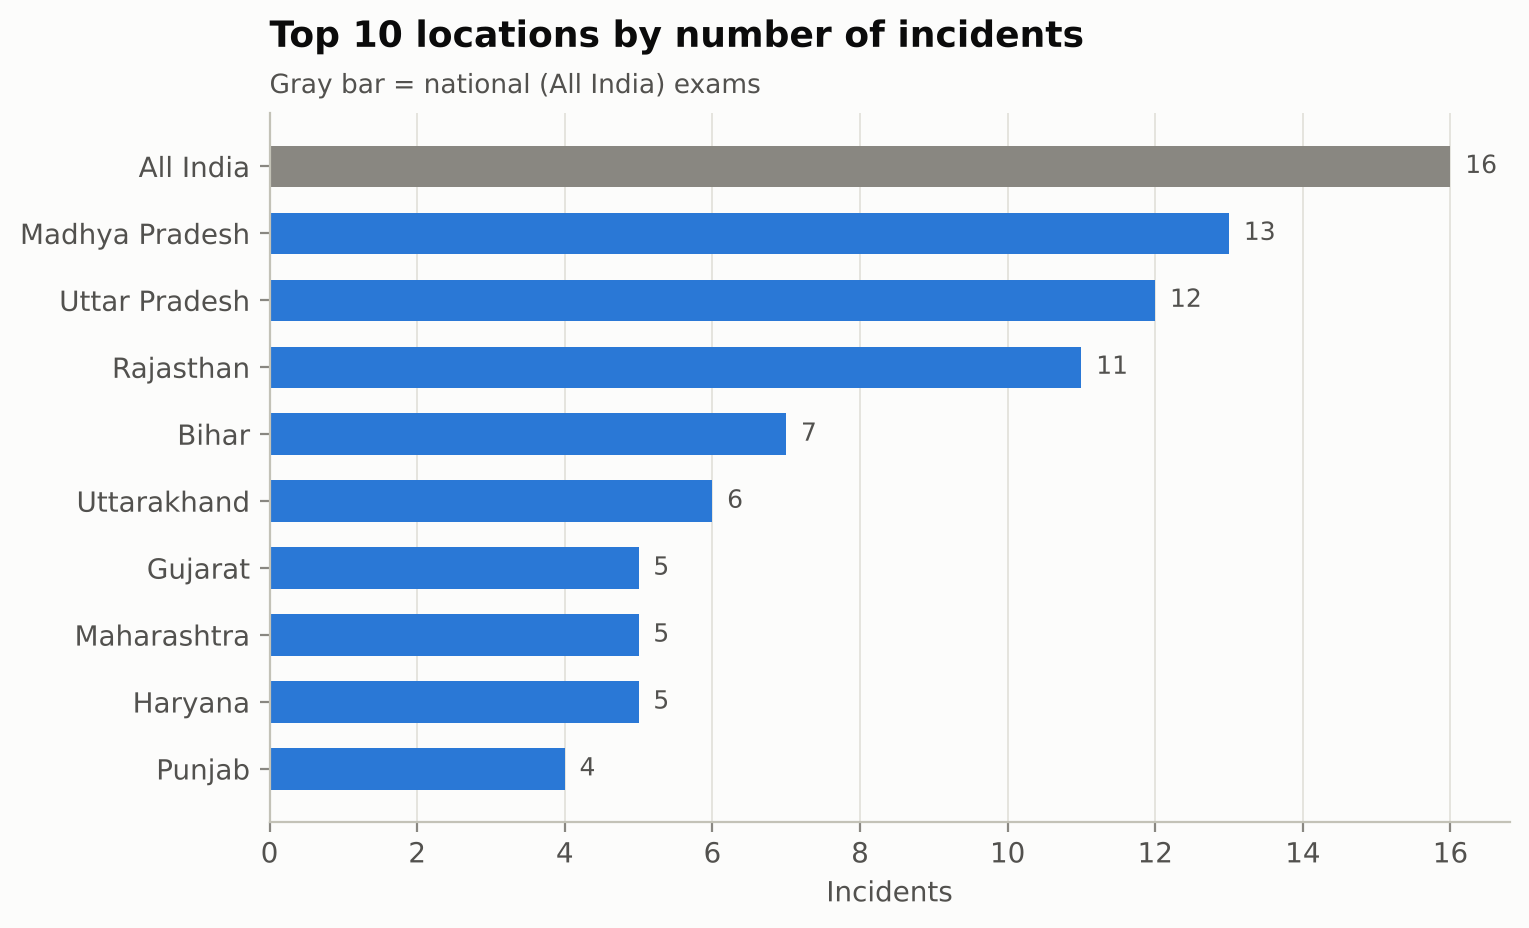

In [4]:
inc["state_clean"] = inc.area.str.replace(r"\s*\(.*?\)", "", regex=True).str.split("/").str[0].str.strip()
top = inc.state_clean.value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top.index, top.values, color=[BLUE if s != "All India" else MUTED for s in top.index], height=0.62)
ax.grid(axis="y", visible=False)
for i, v in enumerate(top.values):
    ax.text(v + 0.2, i, str(v), va="center", fontsize=9, color=INK2)
title(ax, "Top 10 locations by number of incidents", "Gray bar = national (All India) exams")
ax.set_xlabel("Incidents")
save(fig, "A2_top_states")

### A3. Leak status and who conducted the exam

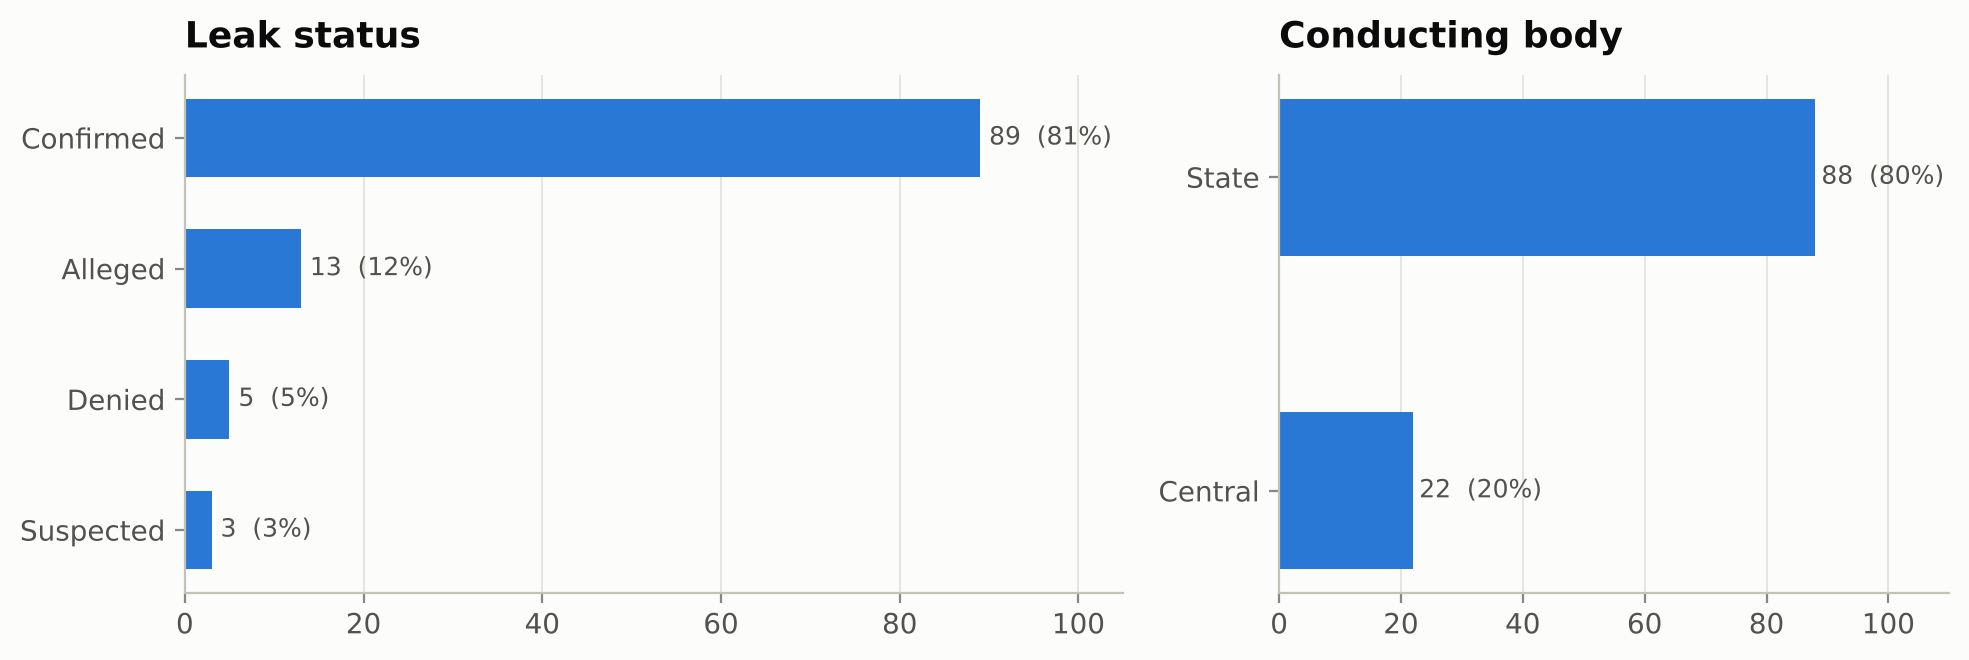

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1.4, 1]})
st = inc.leak_status.value_counts().reindex(["Confirmed", "Alleged", "Suspected", "Denied"]).sort_values()
axes[0].barh(st.index, st.values, color=BLUE, height=0.6)
for i, v in enumerate(st.values):
    axes[0].text(v + 1, i, f"{v}  ({v/len(inc):.0%})", va="center", fontsize=9, color=INK2)
axes[0].grid(axis="y", visible=False); axes[0].set_xlim(0, 105)
title(axes[0], "Leak status")
bt = inc.body_type.value_counts().sort_values()
axes[1].barh(bt.index, bt.values, color=BLUE, height=0.5)
for i, v in enumerate(bt.values):
    axes[1].text(v + 1, i, f"{v}  ({v/len(inc):.0%})", va="center", fontsize=9, color=INK2)
axes[1].grid(axis="y", visible=False); axes[1].set_xlim(0, 110)
title(axes[1], "Conducting body")
fig.tight_layout()
save(fig, "A3_status_and_body")

### A4. What action was taken?

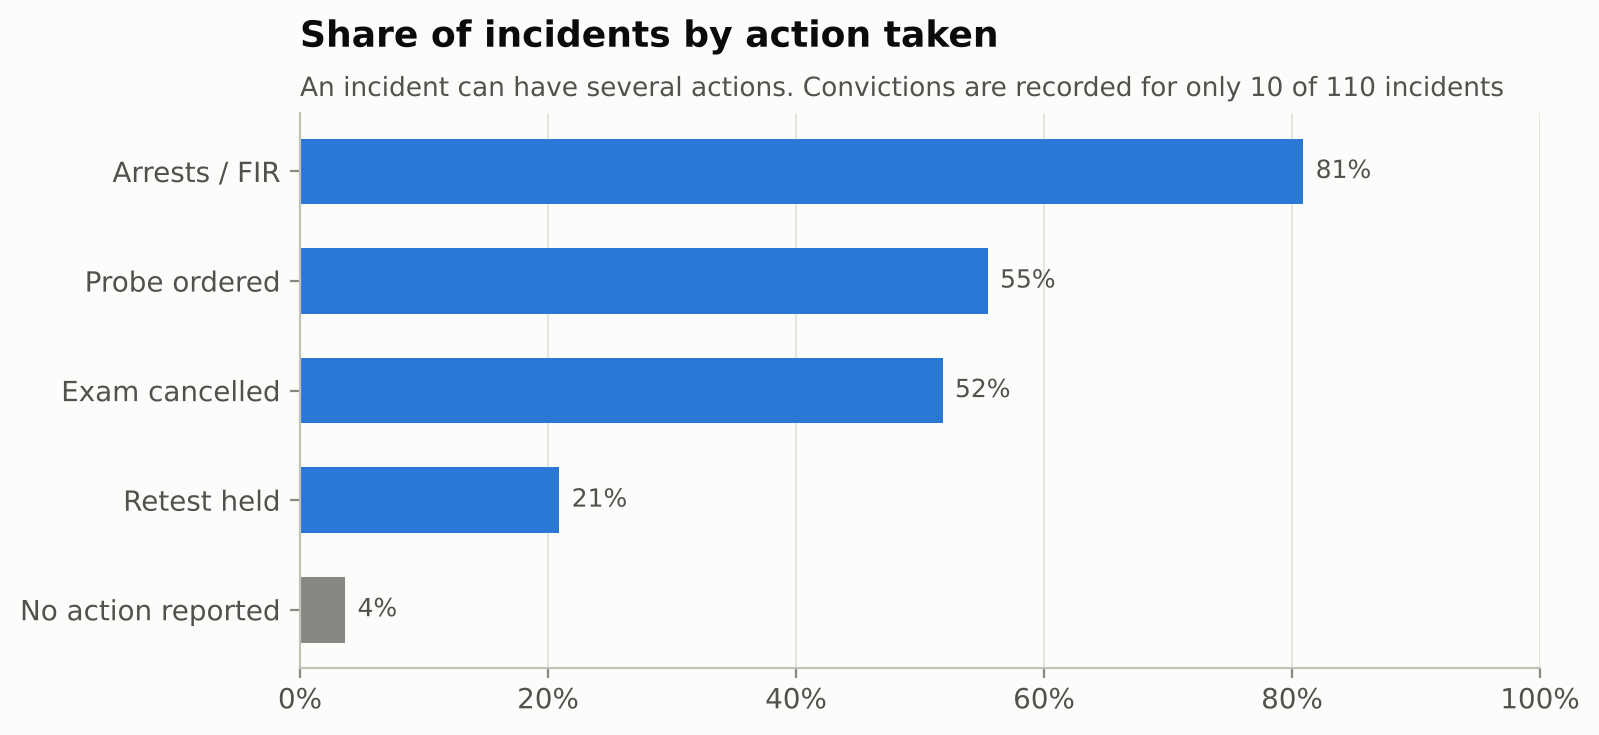

In [6]:
act = inc.action_taken.str.lower()
actions = pd.Series({
    "Arrests / FIR": act.str.contains("arrest").mean(),
    "Exam cancelled": act.str.contains("cancel").mean(),
    "Probe ordered": act.str.contains("probe").mean(),
    "Retest held": act.str.contains("retest").mean(),
    "No action reported": act.str.contains("none reported").mean(),
}).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(actions.index, actions.values, color=[MUTED if i == "No action reported" else BLUE for i in actions.index], height=0.6)
for i, v in enumerate(actions.values):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9, color=INK2)
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.grid(axis="y", visible=False)
conv = inc.convictions.notna().sum()
title(ax, "Share of incidents by action taken", f"An incident can have several actions. Convictions are recorded for only {conv} of {len(inc)} incidents")
save(fig, "A4_actions_taken")

---
## Part B – The comment dataset

### B1. Overview

In [7]:
overview = pd.Series({
    "Comments": len(df),
    "Incidents covered": df.incident_id.nunique(),
    "Platforms (FL clients)": df.platform.nunique(),
    "Languages": df.language.nunique(),
    "Avg words per comment": round(df.text.str.split().str.len().mean(), 1),
    "Date range": f"{df.posted_at.min():%b %Y} – {df.posted_at.max():%b %Y}",
})
display(overview.to_frame("value"))
print(df.label.value_counts())
display(df.sample(8, random_state=1)[["platform", "language", "label", "text"]])

,value
Comments,100002
Incidents covered,110
Platforms (FL clients),5
Languages,4
Avg words per comment,12.2
Date range,Apr 2004 – Nov 2026


label
neutral     33334
negative    33334
positive    33334
Name: count, dtype: int64


,platform,language,label,text
3915,Instagram,en,neutral,Reading about the NEET 2026 case for a college...
28069,X,hinglish,negative,"Ok so ye leak nhi business hai bhai, poora gan..."
93143,YouTube,en,negative,Wow. Army soldier GD exam cancellled 🤬 #stoppa...
51846,YouTube,hinglish,positive,"gusa to aaya tha, par students ki awaaz suni g..."
55195,YouTube,en,neutral,14 persons held 👍
26894,Reddit,en,positive,"Listen, proud of how calm our youngsters have ..."
19814,X,hinglish,positive,"badhiya! accha kiya cancel karke, sabko baraba..."
75862,Reddit,en,neutral,"Honestly, not again. Not again. How many times..."


### B2. Label distribution

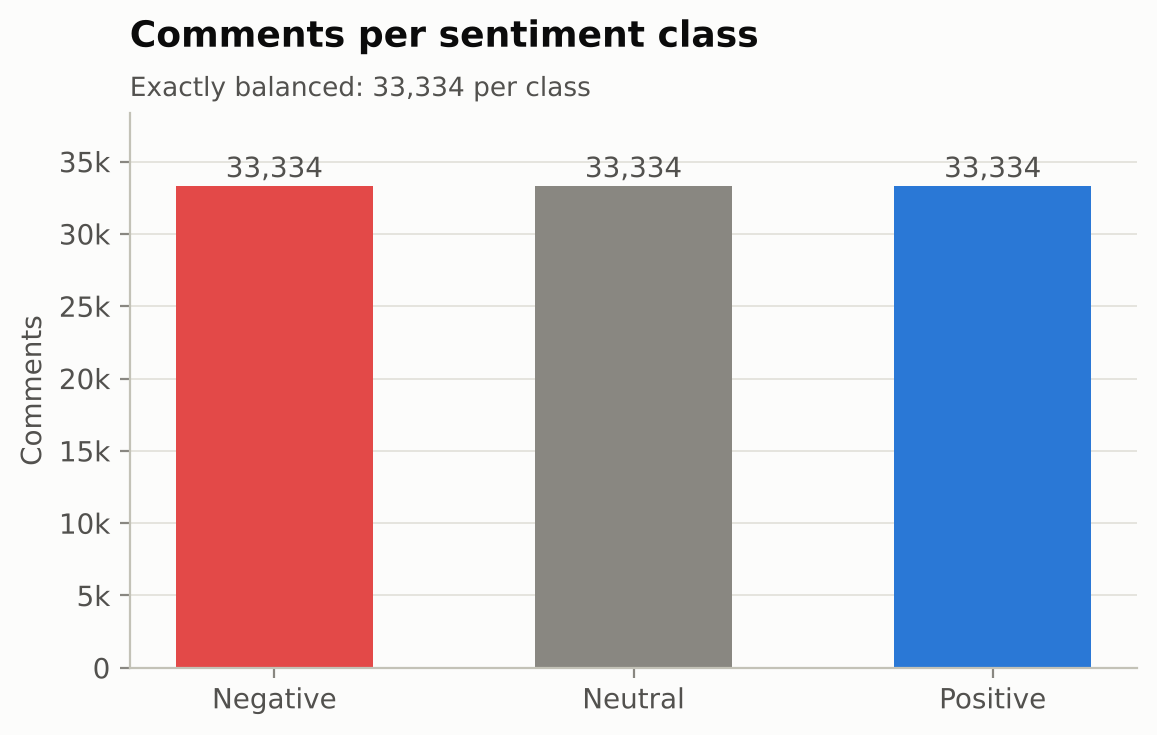

In [8]:
counts = df.label.value_counts().reindex(ORDER)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar([c.capitalize() for c in ORDER], counts.values, color=[SENT[c] for c in ORDER], width=0.55)
ax.grid(axis="x", visible=False)
for i, v in enumerate(counts.values):
    ax.text(i, v + 600, f"{v:,}", ha="center", fontsize=10, color=INK2)
ax.set_ylim(0, counts.max() * 1.15); ax.set_ylabel("Comments")
ax.yaxis.set_major_formatter(kfmt)
title(ax, "Comments per sentiment class", "Exactly balanced: 33,334 per class")
save(fig, "B2_label_distribution")

### B3. Sentiment mix per platform – the federated clients
Each platform will be one FL client. Their sentiment mix is **different (non-IID)**, the realistic setting federated learning has to handle.

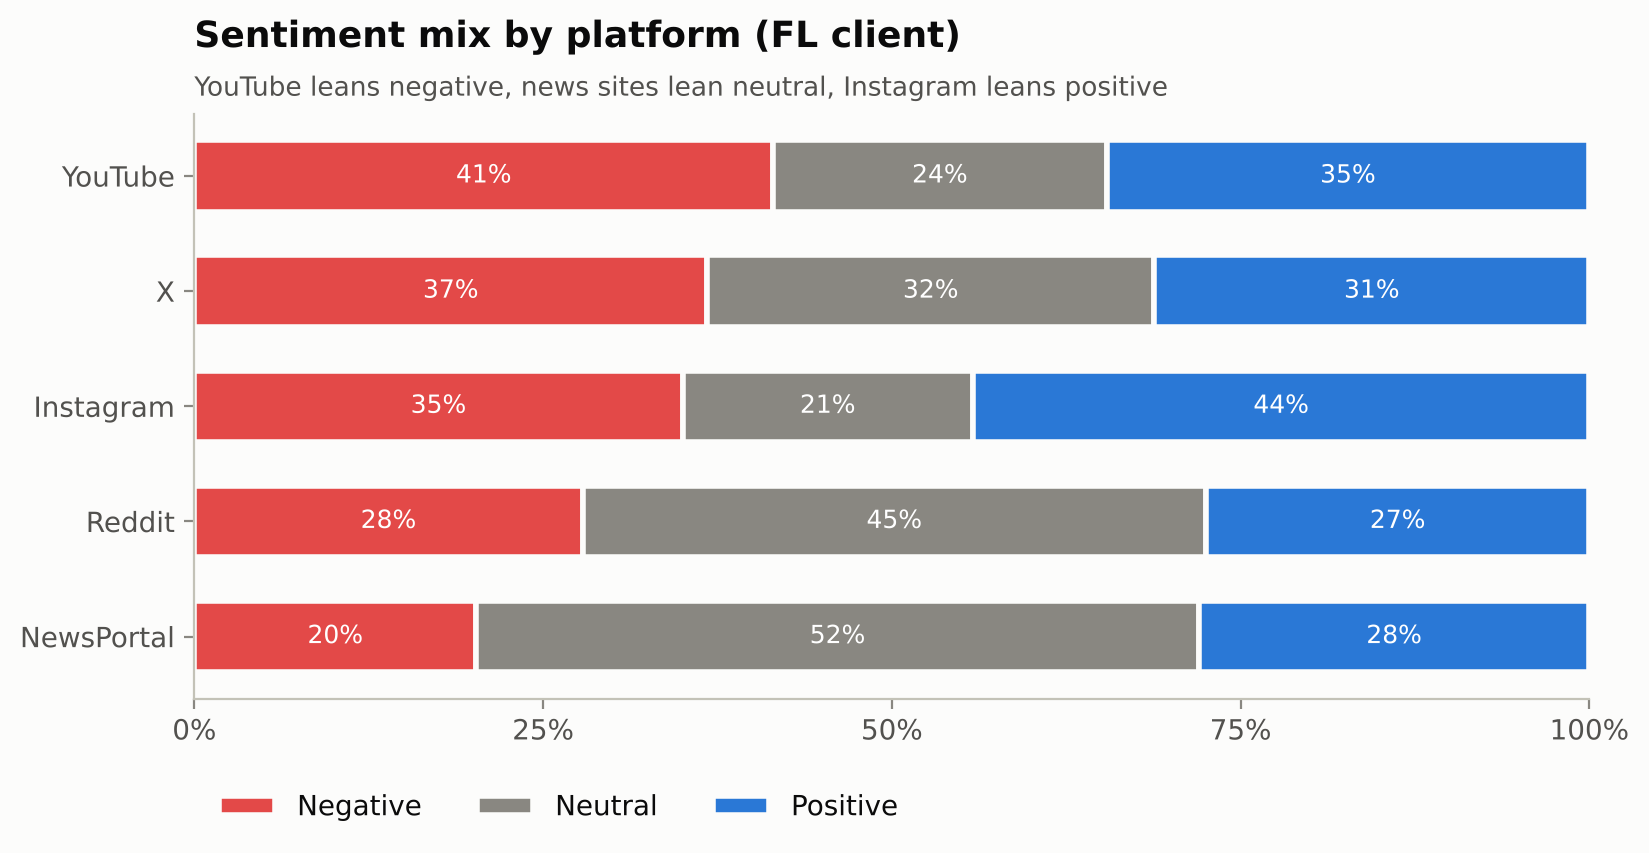

In [9]:
mix = pd.crosstab(df.platform, df.label, normalize="index").reindex(PLATFORMS)[ORDER]
fig, ax = plt.subplots(figsize=(9, 3.8))
stacked_share(ax, mix, SENT)
title(ax, "Sentiment mix by platform (FL client)", "YouTube leans negative, news sites lean neutral, Instagram leans positive")
save(fig, "B3_sentiment_by_platform")
mix.round(3).to_csv(TAB / "sentiment_by_platform.csv")

### B4. Comments per platform and language

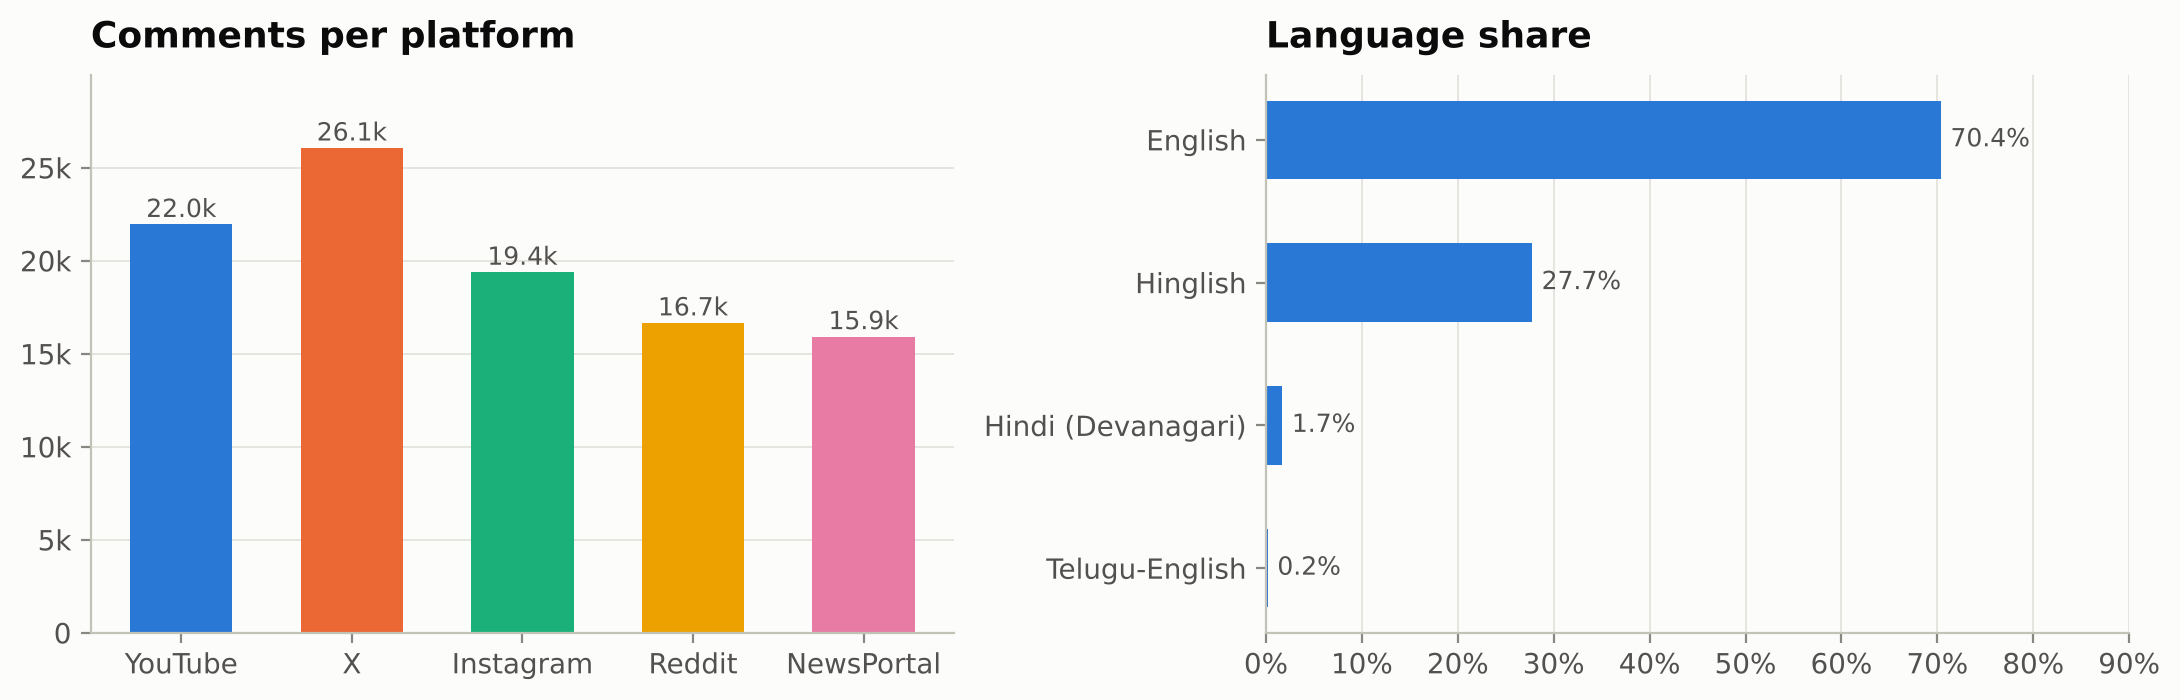

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
pc = df.platform.value_counts().reindex(PLATFORMS)
axes[0].bar(pc.index, pc.values, color=[PCOL[p] for p in pc.index], width=0.6)
for i, v in enumerate(pc.values):
    axes[0].text(i, v + 400, f"{v/1000:.1f}k", ha="center", fontsize=9, color=INK2)
axes[0].grid(axis="x", visible=False); axes[0].yaxis.set_major_formatter(kfmt)
axes[0].set_ylim(0, pc.max() * 1.15)
title(axes[0], "Comments per platform")
names = {"en": "English", "hinglish": "Hinglish", "hi": "Hindi (Devanagari)", "te-en": "Telugu-English"}
lc = df.language.map(names).value_counts(normalize=True).sort_values()
axes[1].barh(lc.index, lc.values, color=BLUE, height=0.55)
for i, v in enumerate(lc.values):
    axes[1].text(v + 0.01, i, f"{v:.1%}", va="center", fontsize=9, color=INK2)
axes[1].set_xlim(0, 0.9); axes[1].xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); axes[1].grid(axis="y", visible=False)
title(axes[1], "Language share")
fig.tight_layout()
save(fig, "B4_platform_and_language")

### B5. Sentiment by exam type and by language

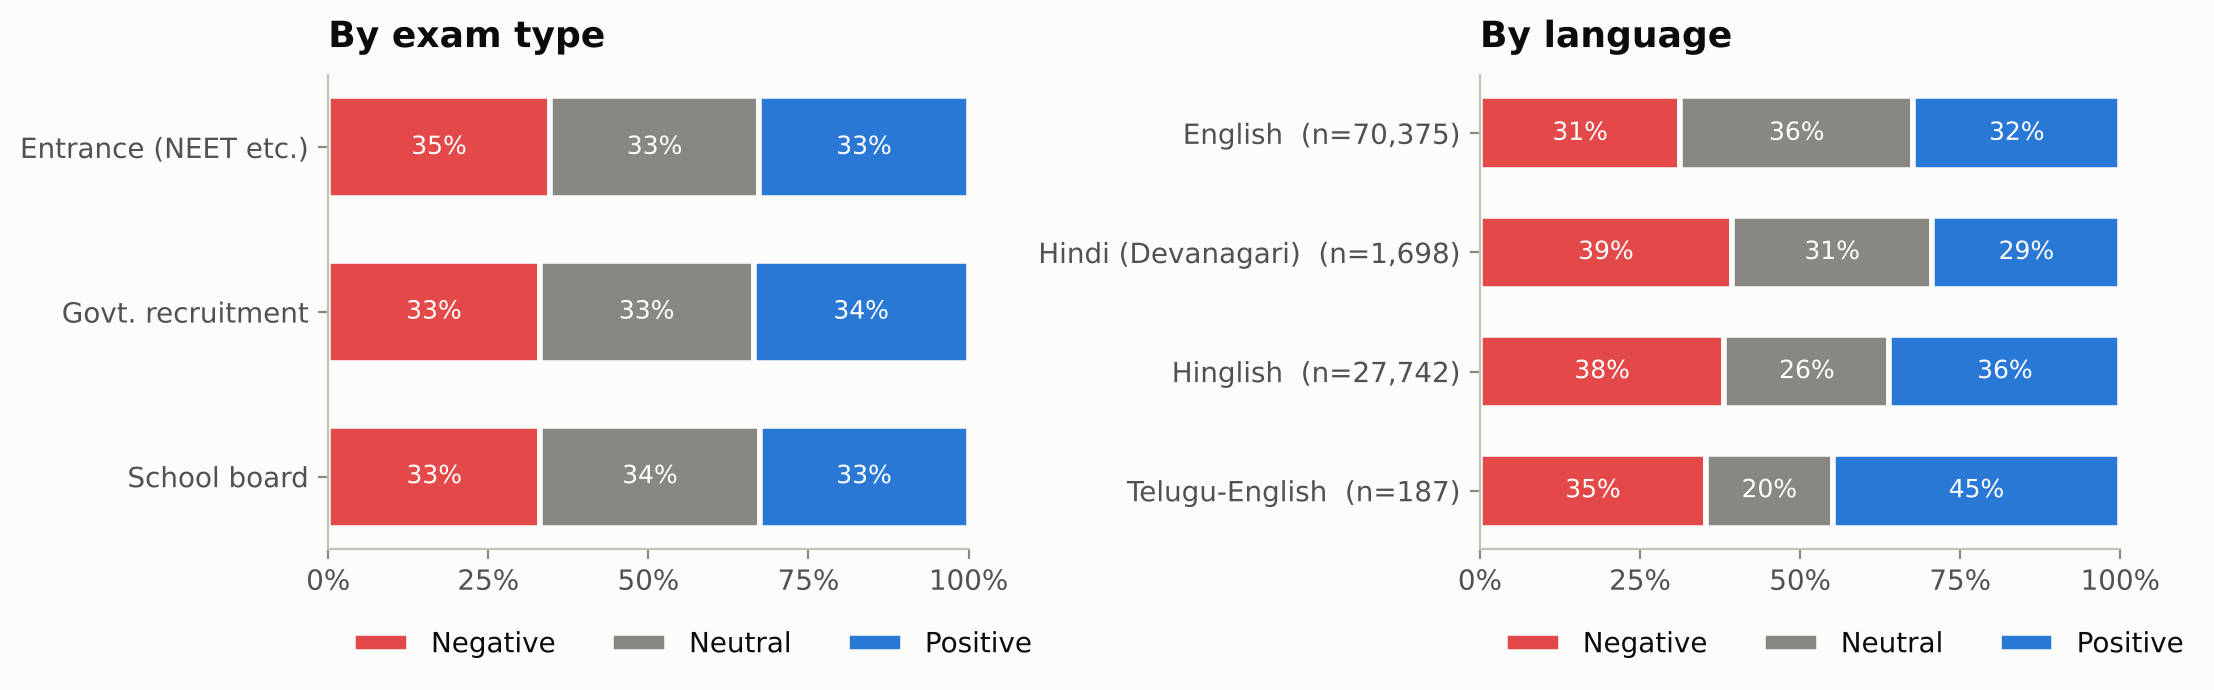

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
cat = pd.crosstab(df.exam_category.map({"recruit": "Govt. recruitment", "entrance": "Entrance (NEET etc.)", "board": "School board"}),
                  df.label, normalize="index")[ORDER]
stacked_share(axes[0], cat, SENT)
title(axes[0], "By exam type")
lang = pd.crosstab(df.language.map(names), df.label, normalize="index")[ORDER]
lang.index = [f"{l}  (n={(df.language.map(names) == l).sum():,})" for l in lang.index]
stacked_share(axes[1], lang, SENT)
title(axes[1], "By language")
fig.tight_layout()
save(fig, "B5_sentiment_by_category_language")

### B6. Comment length

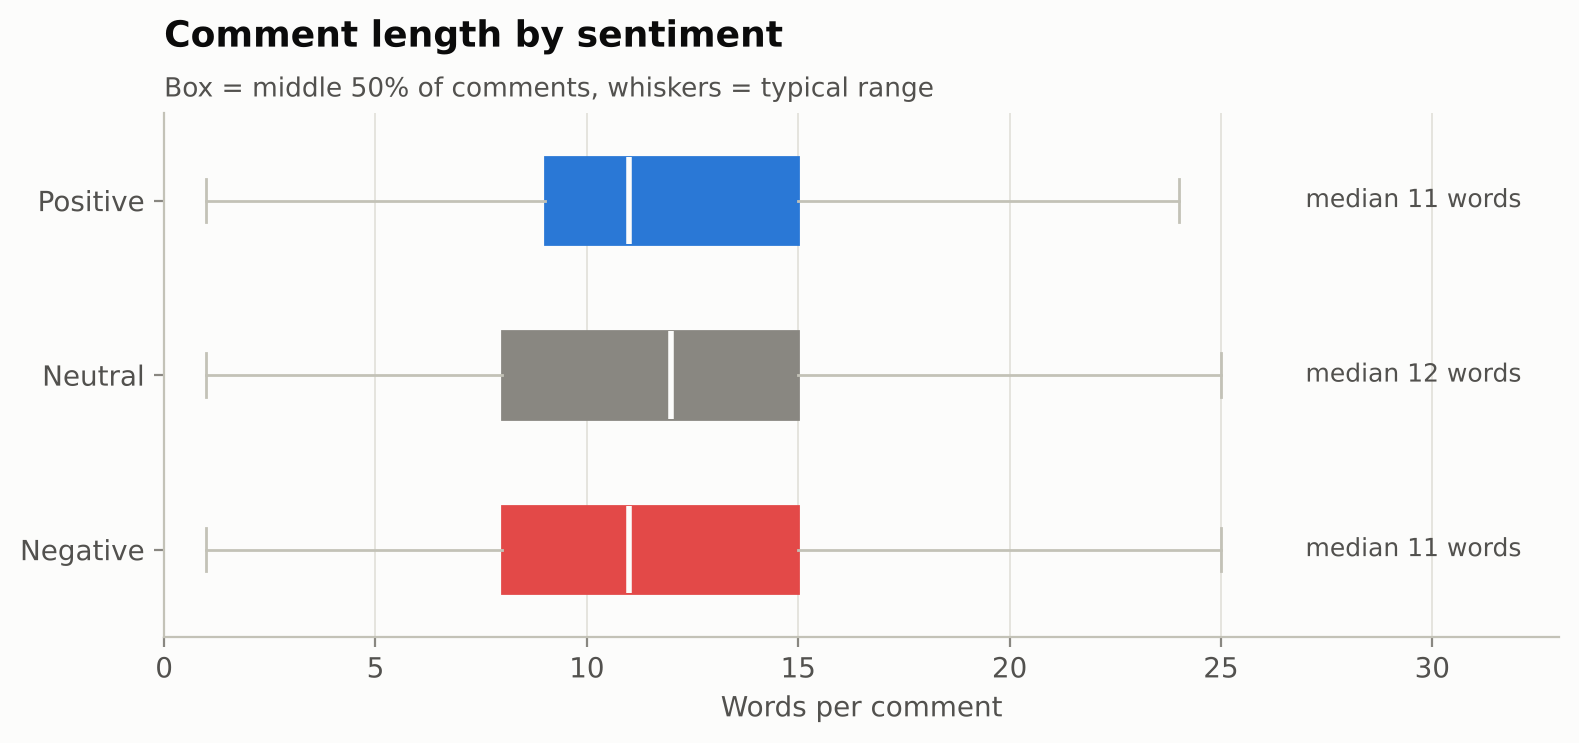

In [12]:
df["words"] = df.text.str.split().str.len()
fig, ax = plt.subplots(figsize=(9, 3.4))
data = [df.loc[df.label == c, "words"] for c in ORDER]
import matplotlib
orient = {"orientation": "horizontal"} if tuple(map(int, matplotlib.__version__.split(".")[:2])) >= (3, 10) else {"vert": False}
bp = ax.boxplot(data, **orient, widths=0.5, patch_artist=True, showfliers=False,
                medianprops=dict(color=SURFACE, linewidth=2), whiskerprops=dict(color=AXIS), capprops=dict(color=AXIS))
for patch, c in zip(bp["boxes"], ORDER):
    patch.set_facecolor(SENT[c]); patch.set_edgecolor(SENT[c])
ax.set_yticks([1, 2, 3], [c.capitalize() for c in ORDER]); ax.grid(axis="y", visible=False)
for i, c in enumerate(ORDER, start=1):
    ax.text(27, i, f"median {df.loc[df.label == c, 'words'].median():.0f} words",
            va="center", fontsize=9, color=INK2)
ax.set_xlim(0, 33); ax.set_xlabel("Words per comment")
title(ax, "Comment length by sentiment", "Box = middle 50% of comments, whiskers = typical range")
save(fig, "B6_comment_length")

### B7. Comments over time

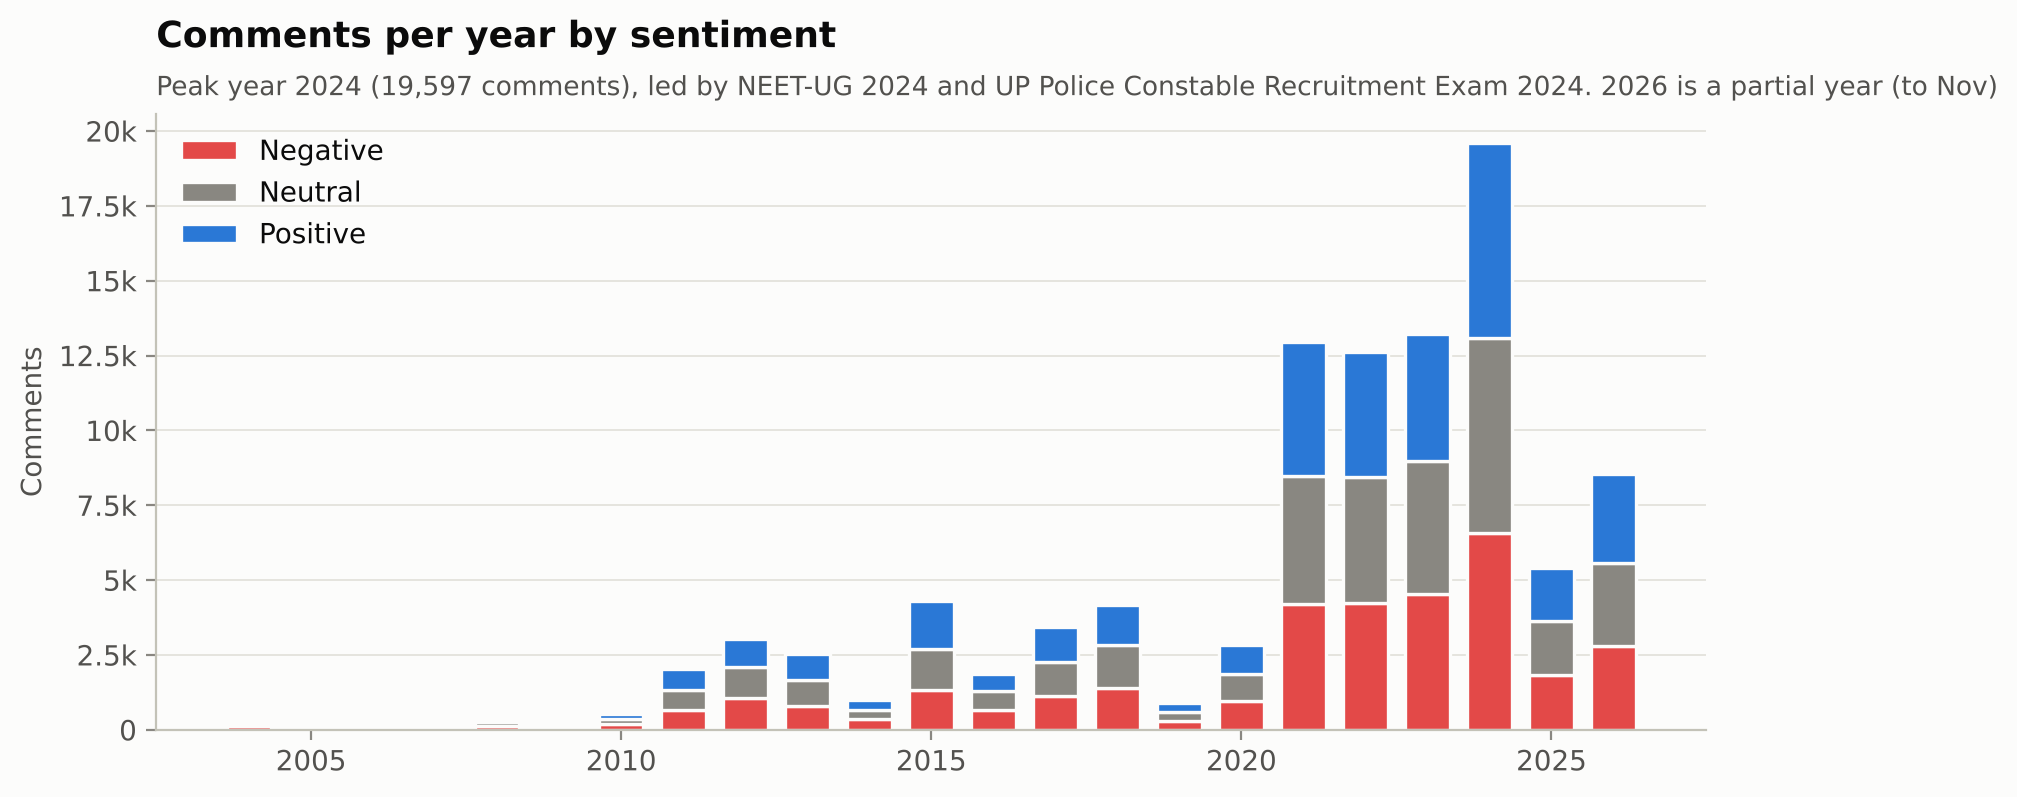

In [13]:
by_year = pd.crosstab(df.posted_at.dt.year, df.label)[ORDER]
fig, ax = plt.subplots(figsize=(10, 4))
bottom = np.zeros(len(by_year))
for c in ORDER:
    ax.bar(by_year.index, by_year[c], bottom=bottom, color=SENT[c], edgecolor=SURFACE, linewidth=1.2, width=0.72, label=c.capitalize())
    bottom += by_year[c].values
ax.grid(axis="x", visible=False); ax.yaxis.set_major_formatter(kfmt)
ax.set_ylabel("Comments"); ax.legend(loc="upper left")
peak = by_year.sum(axis=1).idxmax()
peak_inc = df[df.posted_at.dt.year == peak].incident_id.value_counts().index[:2]
names_peak = " and ".join(short(inc.set_index("incident_id").loc[i, "exam_name"], 45) for i in peak_inc)
title(ax, "Comments per year by sentiment",
      f"Peak year {peak} ({by_year.loc[peak].sum():,} comments), led by {names_peak}. 2026 is a partial year (to Nov)")
save(fig, "B7_comments_over_time")

### B8. Most-discussed incidents

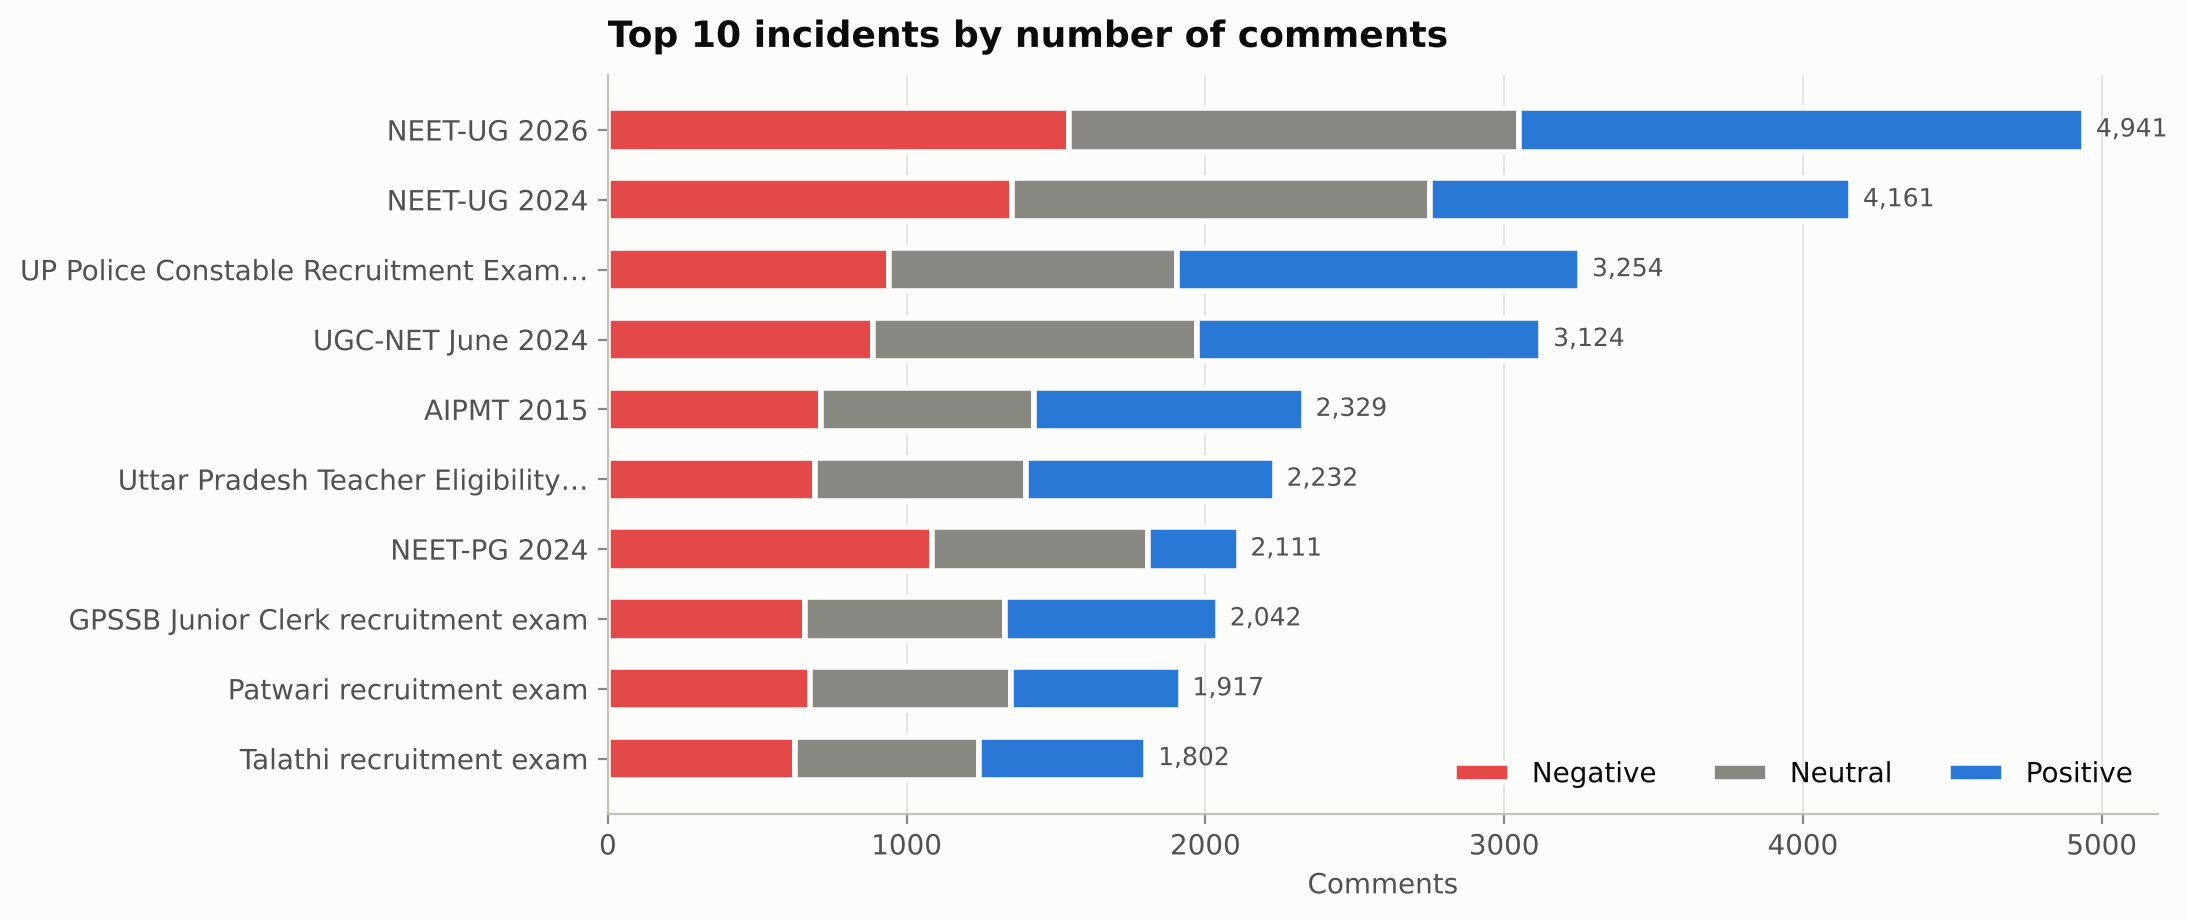

In [14]:
top_inc = df.groupby("incident_id").size().sort_values(ascending=False).head(10).index
t = pd.crosstab(df[df.incident_id.isin(top_inc)].incident_id, df.label)[ORDER].loc[top_inc]
t.index = [short(inc.set_index("incident_id").loc[i, "exam_name"]) for i in t.index]
fig, ax = plt.subplots(figsize=(10, 4.8))
left = np.zeros(len(t))
for c in ORDER:
    ax.barh(t.index, t[c], left=left, color=SENT[c], edgecolor=SURFACE, linewidth=2, height=0.62, label=c.capitalize())
    left += t[c].values
for i, v in enumerate(left):
    ax.text(v + 40, i, f"{v:,.0f}", va="center", fontsize=9, color=INK2)
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.legend(ncol=3, loc="lower right")
ax.set_xlabel("Comments")
title(ax, "Top 10 incidents by number of comments")
save(fig, "B8_top_incidents")

### B9. Words that set each sentiment apart
Words that are much more common in one class than in the other two (English and Hinglish; hashtags and common filler words removed).

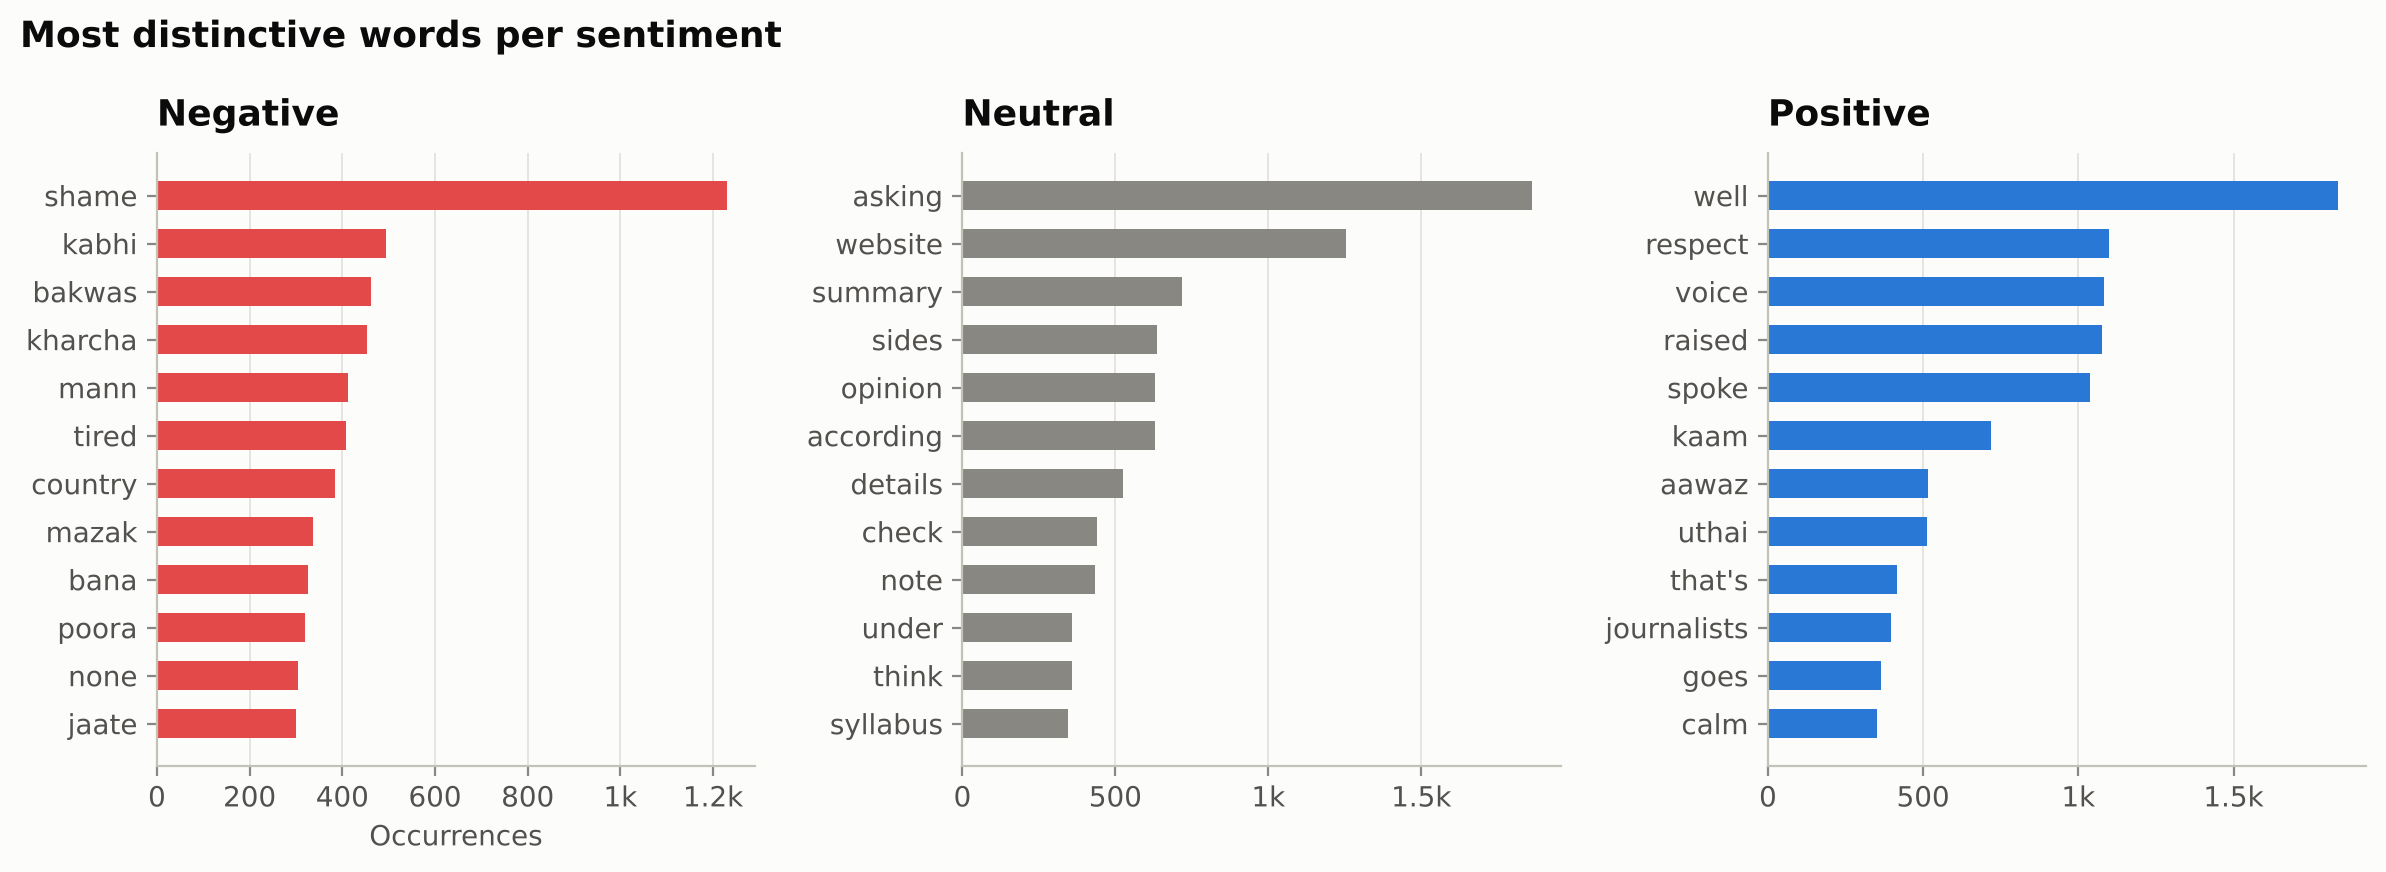

In [15]:
STOP = set("""the a an and or but if of to in on at for with is are was were be been it this that these those
i we you he she they my our your their me us them its as by from so not no just very more most will would can
could should do does did have has had about there what which who how when why all any some than then also only
ka ki ke hai ho me se ko ye wo bhi to na kya ab hi par aur ek nahi bhai yaar bro guys sir ok so""".split())
no_tags = df.text.str.lower().str.replace(r"#\w+", " ", regex=True)          # hashtags removed
tok = df.assign(tokens=no_tags.str.findall(r"[a-z][a-z']{2,}"))
counts = {c: Counter(w for ws in tok.loc[tok.label == c, "tokens"] for w in ws if w not in STOP) for c in ORDER}
exam_words = set(" ".join(a.lower() for a in inc.exam_name).split()) | {"neet", "paper", "exam", "leak", "case", "leaked"}
fig, axes = plt.subplots(1, 3, figsize=(12, 4.4))
for ax, c in zip(axes, ORDER):
    other = counts[ORDER[0]] + counts[ORDER[1]] + counts[ORDER[2]] - counts[c]
    score = {w: (n + 1) / (other.get(w, 0) + 1) * np.log(n) for w, n in counts[c].items() if n >= 300 and w not in exam_words}
    best = pd.Series(score).sort_values(ascending=False).head(12)
    freq = pd.Series({w: counts[c][w] for w in best.index}).sort_values()
    ax.barh(freq.index, freq.values, color=SENT[c], height=0.6)
    ax.grid(axis="y", visible=False); ax.xaxis.set_major_formatter(kfmt)
    title(ax, c.capitalize())
axes[0].set_xlabel("Occurrences")
fig.suptitle("Most distinctive words per sentiment", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "B9_distinctive_words")

### B10. Who is commenting?

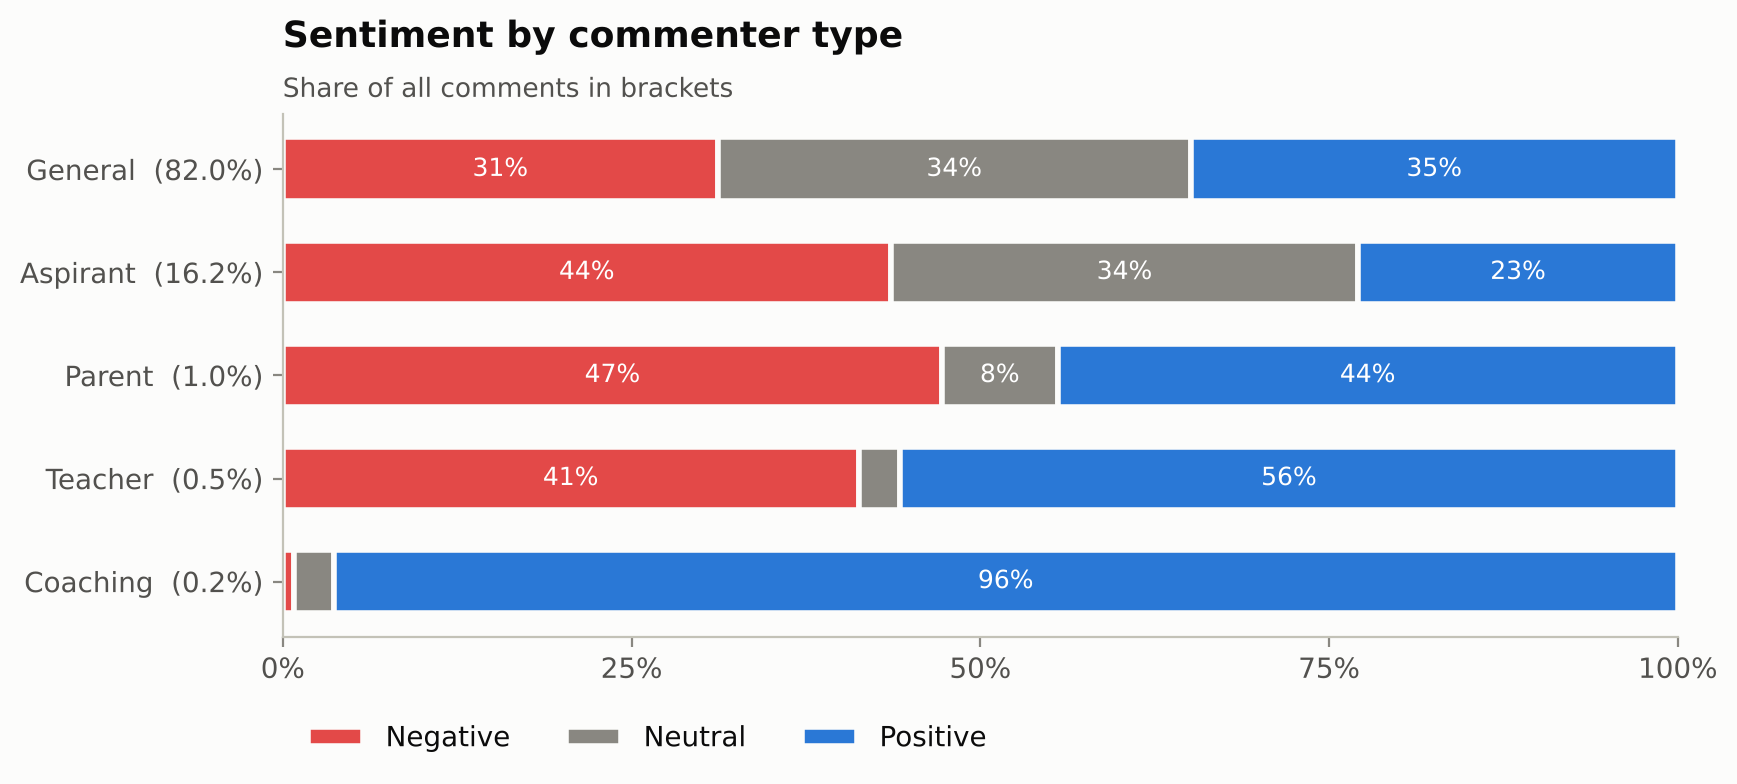

In [16]:
ut = pd.crosstab(df.user_type, df.label, normalize="index")[ORDER]
ut = ut.loc[df.user_type.value_counts().index]
ut.index = [f"{u.capitalize()}  ({(df.user_type == u).mean():.1%})" for u in ut.index]
fig, ax = plt.subplots(figsize=(9, 3.4))
stacked_share(ax, ut, SENT)
title(ax, "Sentiment by commenter type", "Share of all comments in brackets")
save(fig, "B10_user_type")

### Summary table (saved for the report)

In [17]:
summary = pd.DataFrame({
    "metric": ["Incidents", "Incidents 2021–2024", "Confirmed leaks", "Central / State bodies",
               "Comments", "Per class", "Platforms (FL clients)", "Most negative platform", "Most neutral platform",
               "Most positive platform", "Hinglish + Hindi share", "Median words per comment"],
    "value": [len(inc), int(yr.loc[2021:2024].sum()), int((inc.leak_status == "Confirmed").sum()),
              f"{(inc.body_type == 'Central').sum()} / {(inc.body_type == 'State').sum()}",
              f"{len(df):,}", "33,334", 5, mix.negative.idxmax(), mix.neutral.idxmax(), mix.positive.idxmax(),
              f"{df.language.isin(['hinglish', 'hi']).mean():.1%}", int(df.words.median())],
})
summary.to_csv(TAB / "eda_summary.csv", index=False)
summary

,metric,value
0,Incidents,110
1,Incidents 2021–2024,52
2,Confirmed leaks,89
3,Central / State bodies,22 / 88
4,Comments,"100,002"
5,Per class,"33,334"
6,Platforms (FL clients),5
7,Most negative platform,YouTube
8,Most neutral platform,NewsPortal
9,Most positive platform,Instagram


## Key findings

**Incidents (Part A)**
1. Reported paper leaks rose sharply after 2020. Most incidents in the dataset fall between 2021 and 2024.
2. Leaks are mainly a **state-level** problem: about 4 in 5 incidents involve state bodies, led by Madhya Pradesh (Vyapam), Rajasthan and Uttar Pradesh.
3. Arrests and FIRs are common, but **convictions are almost never recorded**. That gap explains much of the public's negative sentiment.

**Comments (Part B)**
4. The dataset is exactly balanced (33,334 per class), so accuracy and macro-F1 can be compared fairly. About 7.6% of labels include simulated annotator disagreement on ambiguous comments (see the dataset card).
5. Platforms differ clearly in sentiment mix: YouTube leans negative, news sites lean neutral, Instagram leans positive. This **non-IID split** is exactly the situation federated learning is designed for, and it motivates Steps 6–8.
6. About 3 in 10 comments are in Hinglish or Hindi, and the share differs by platform (most on YouTube, almost none on news sites). Preprocessing (Step 4) must handle code-mixed text, and a model trained on one platform alone may struggle with another platform's language.
7. Distinctive words match the label definitions (anger and distrust vs. relief and praise vs. questions), which supports the labeling.

**Next:** Step 4 – preprocessing (cleaning, tokenization, TF-IDF, train/test split).